In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns

from sklearn.metrics import r2_score

from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LinearRegression

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

In [147]:
df = pd.read_csv('concrete_data.csv')

In [148]:
df.sample(5)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
116,374.0,189.2,0.0,170.1,10.1,926.1,756.7,28,61.09
262,212.6,0.0,100.4,159.4,10.4,1003.8,903.8,56,44.40
112,439.0,177.0,0.0,186.0,11.1,884.9,707.9,7,56.10
742,480.0,0.0,0.0,192.0,0.0,936.0,721.0,90,54.28
874,313.0,0.0,113.0,178.0,8.0,1002.0,689.0,28,36.80


In [149]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [150]:
# check negative values are there or not
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [151]:
x = df.drop(columns=['Strength'])
y = df.iloc[:,-1]

In [152]:
x_train, x_test, y_train, y_test = train_test_split(
    x,y,test_size = 0.2, random_state=42
)

In [153]:
x

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360
...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28


In [154]:
y

0       79.99
1       61.89
2       40.27
3       41.05
4       44.30
        ...  
1025    44.28
1026    31.18
1027    23.70
1028    32.77
1029    32.40
Name: Strength, Length: 1030, dtype: float64

In [155]:
# Before applying power transformation
lr = LinearRegression()
lr.fit(x_train, y_train)

y_pred = lr.predict(x_test)

r2_score(y_test, y_pred)

0.6275531792314848

In [156]:
lr = LinearRegression()
print(np.mean(cross_val_score(lr, x, y, scoring='r2')))

0.4609940491662864


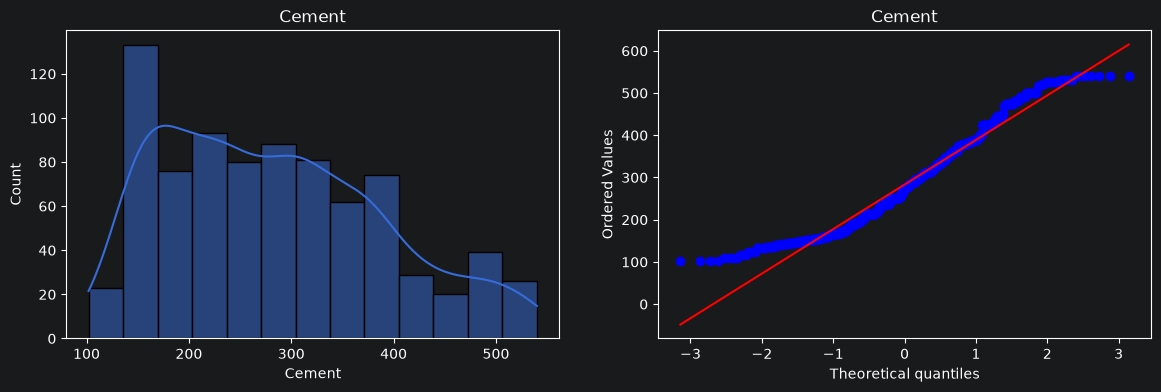

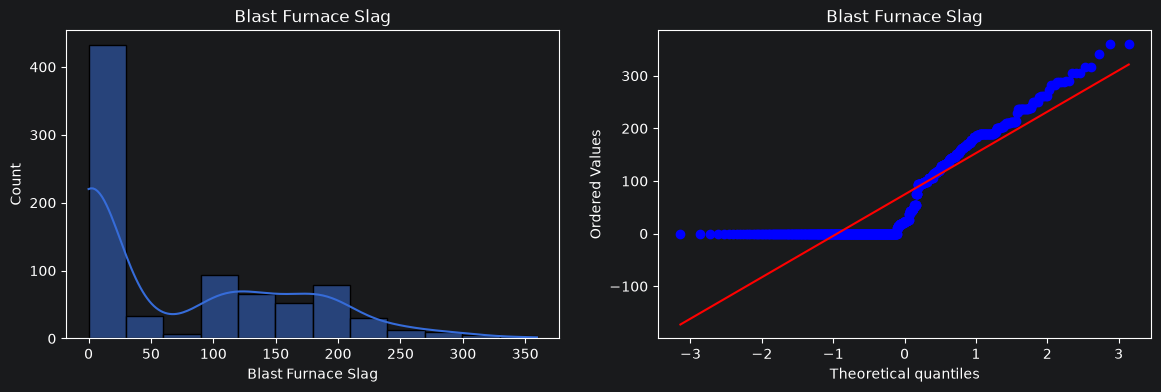

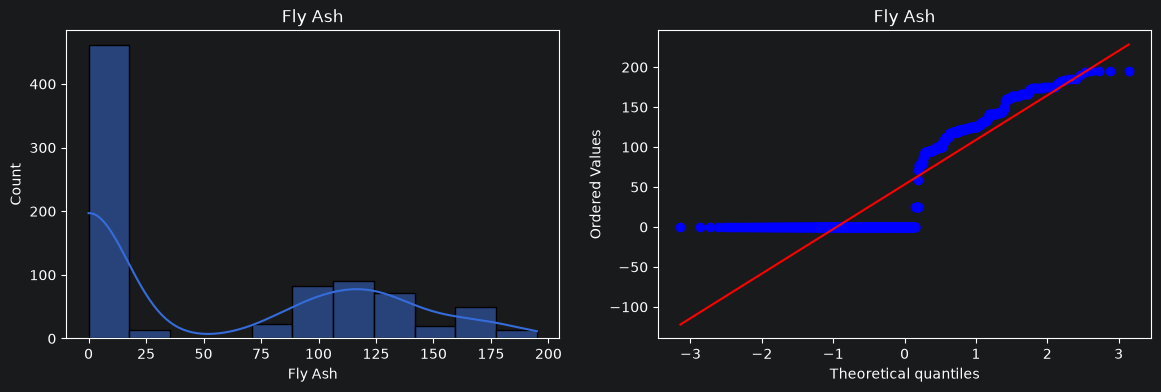

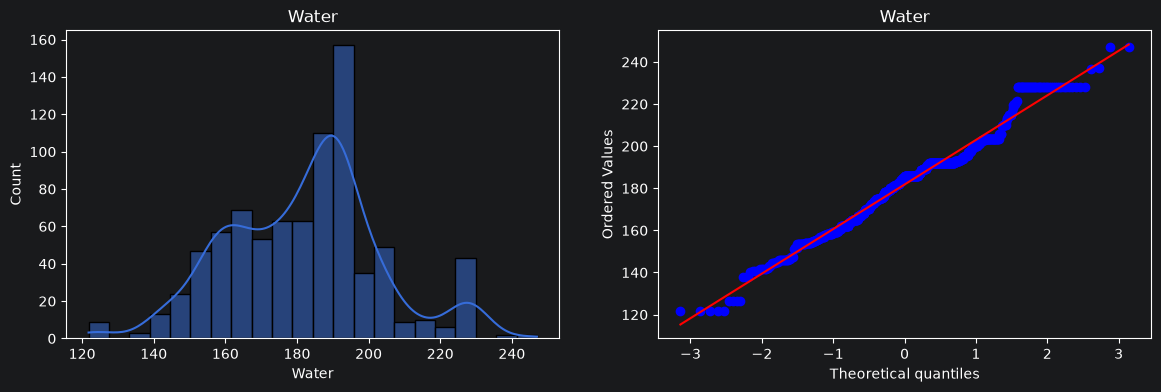

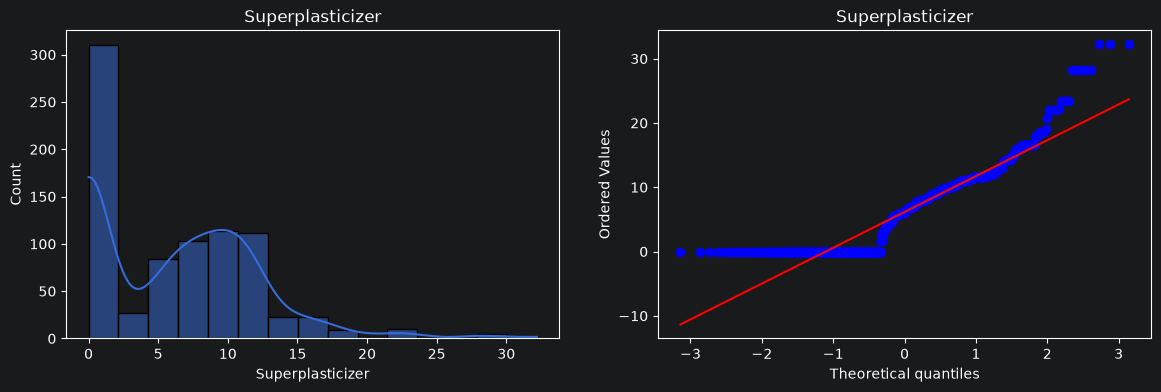

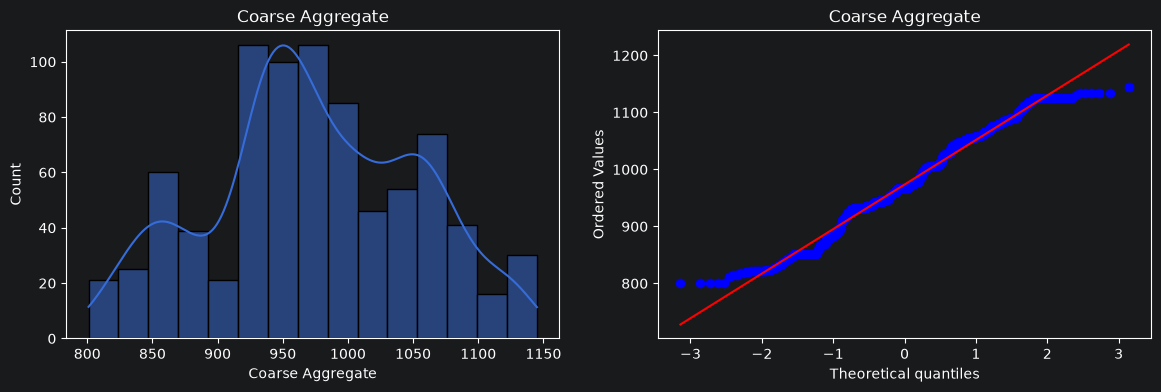

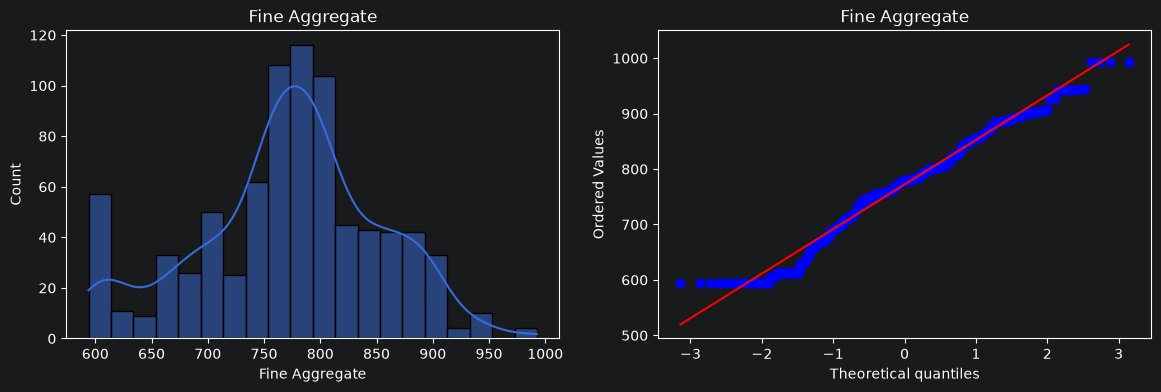

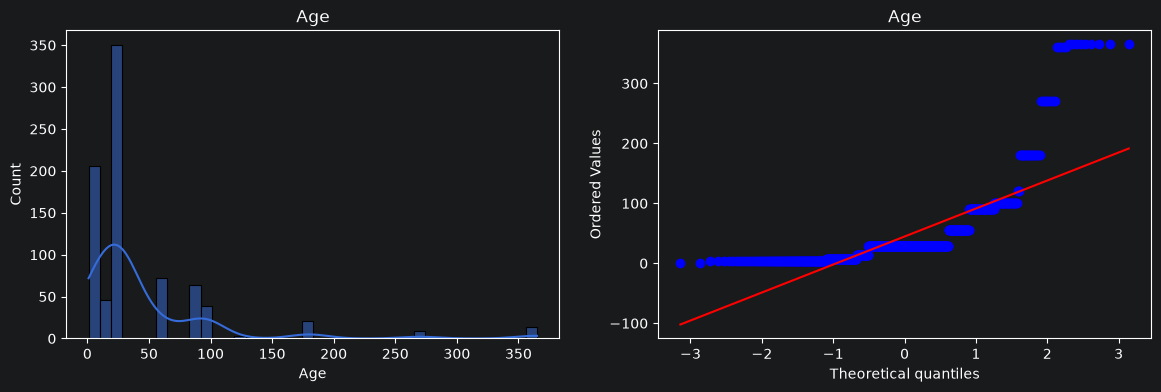

In [157]:
# plotting the distplot without any transformation

for col in x_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(x_train[col], kde=True)
    plt.title(col)

    plt.subplot(122)
    stats.probplot(x_train[col], dist='norm', plot=plt)
    plt.title(col)

In [158]:
# After applying BOX-COX transformer(Power Transformer)
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='box-cox')

In [159]:
x_train_transformed = pt.fit_transform(x_train+0.000001)
x_test_transformed = pt.transform(x_test+0.000001)

In [160]:
pd.DataFrame({'cols':x_train.columns, 'box_cox_lambdas':pt.lambdas_})

,cols,box_cox_lambdas
0,Cement,0.177025
1,Blast Furnace Slag,0.025093
2,Fly Ash,-0.038970
3,Water,0.772682
4,Superplasticizer,0.098811
5,Coarse Aggregate,1.129813
6,Fine Aggregate,1.782018
7,Age,0.066631


In [161]:
pd.DataFrame(x_train_transformed, columns=x_train.columns)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,-1.279751,0.956151,1.128045,-0.301920,0.898506,-0.262500,-0.677568,0.106010
1,1.244706,0.701994,1.137577,-0.165055,0.749235,-1.912728,-0.314062,0.106010
2,0.079842,-1.085667,1.131407,-1.047291,0.788486,1.018407,0.025957,-1.675970
3,-0.145641,0.898125,1.096514,0.581224,0.733792,-1.750779,0.583253,0.106010
4,-1.131044,0.787203,1.133149,-1.105297,0.811152,1.368575,0.262623,-1.675970
...,...,...,...,...,...,...,...,...
819,0.183601,0.997079,-0.887212,-1.769923,0.820684,0.390563,0.358776,-1.675970
820,-0.198733,-1.085667,1.133622,-1.839129,0.838861,1.445973,0.322797,-0.475625
821,-0.844517,-1.085667,1.133681,-0.706089,0.788486,1.345367,0.297157,1.246733
822,1.565624,0.925496,-0.887212,-0.019311,0.761011,-1.537255,0.076211,0.106010


In [162]:
lr = LinearRegression()
lr.fit(x_train_transformed,y_train)

y_pred2 = lr.predict(x_test_transformed)

r2_score(y_test,y_pred2)

0.8047825008078886

In [163]:
# using cross val score

pt = PowerTransformer(method='box-cox')
x_transformed = pt.fit_transform(x+0.000001)

lr = LinearRegression()
np.mean(cross_val_score(lr, x_transformed, y, scoring='r2'))

np.float64(0.6662950326831086)

In [164]:
x_train_transformed = pd.DataFrame(x_train_transformed,columns=x_train.columns)

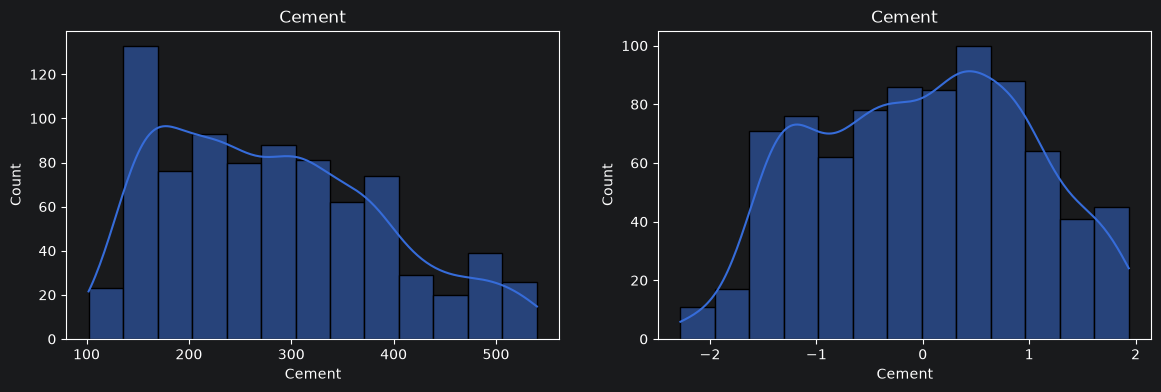

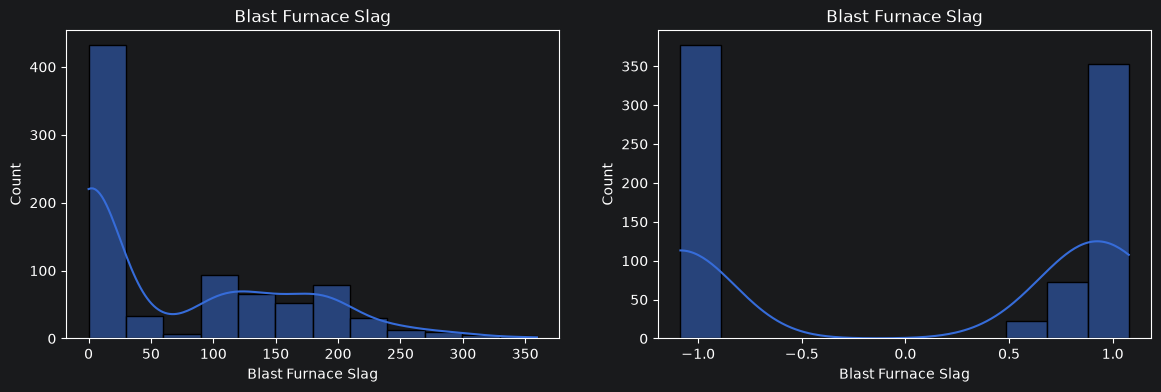

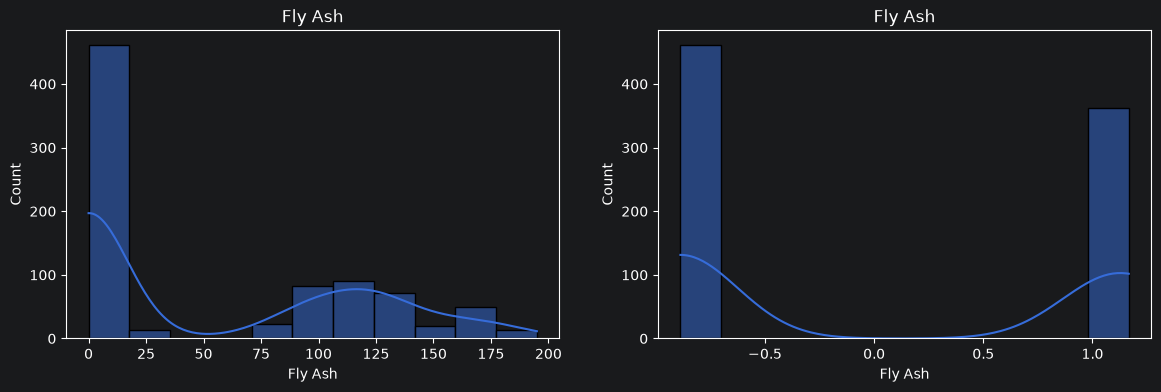

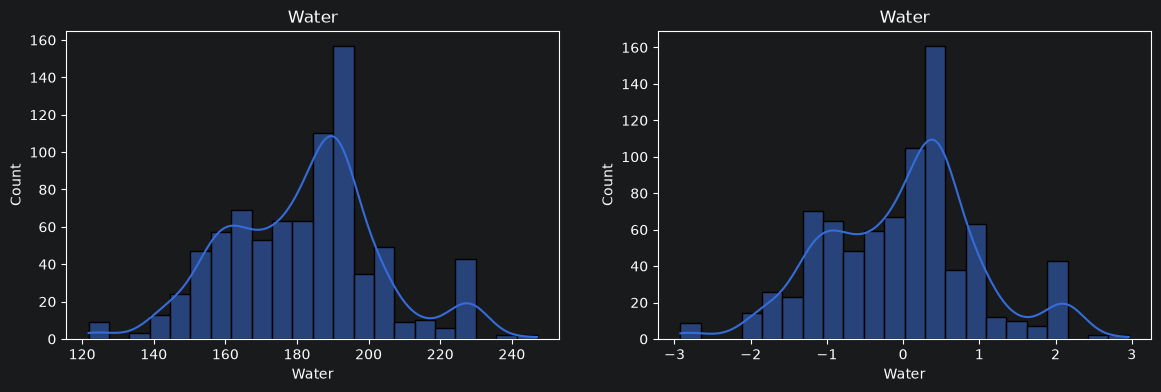

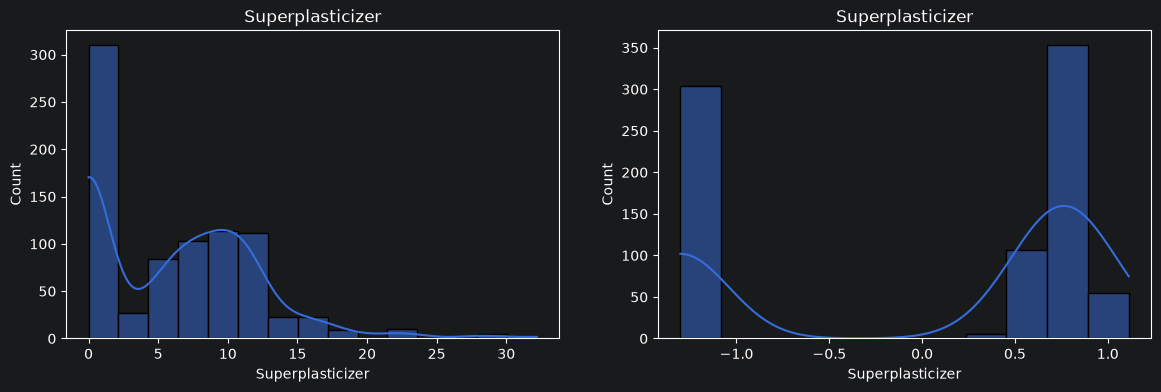

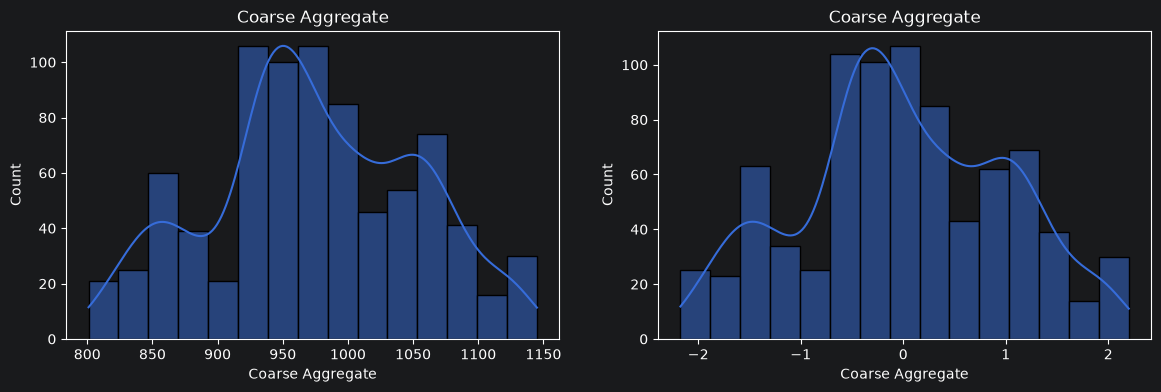

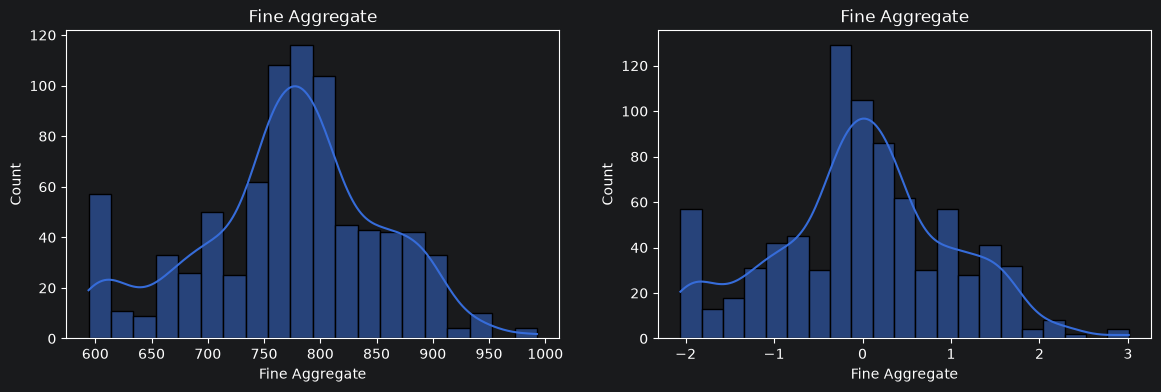

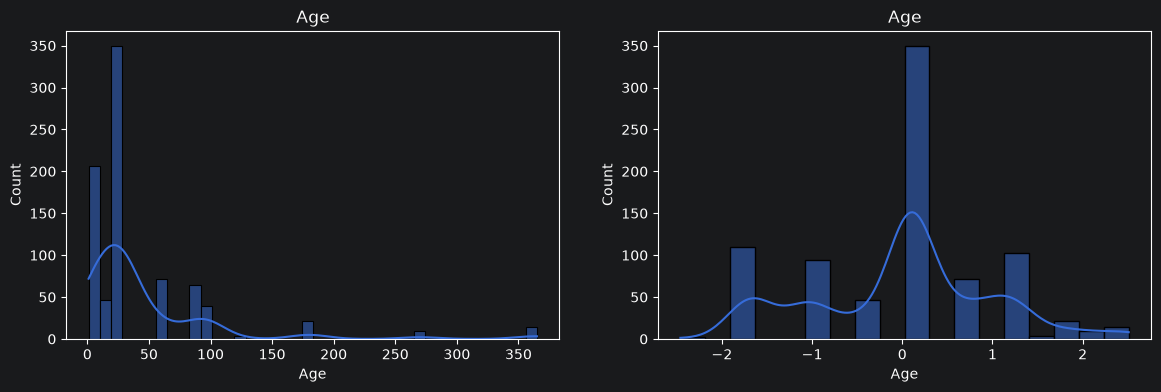

In [165]:
for col in x_train_transformed.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(x_train[col], kde=True)
    plt.title(col)

    plt.subplot(122)
    sns.histplot(x_train_transformed[col], kde=True)
    plt.title(col)

    plt.show()

## Apply Yeo-Johnson transform

In [167]:
# While creating PowerTransformer object Yeo_Johnson object or method is by default selected

pt1 = PowerTransformer()

x_train_transformed1 = pt1.fit_transform(x_train)
x_test_transformed1 = pt1.transform(x_test)

lr2 = LinearRegression()
lr2.fit(x_train_transformed1, y_train)

y_pred3 = lr2.predict(x_test_transformed1)

print(r2_score(y_test, y_pred3))

0.8161906510869553


In [170]:
pt = PowerTransformer()
x_transformed1 = pt.fit_transform(x)

lr = LinearRegression()
np.mean(cross_val_score(lr,x_transformed1,y,scoring='r2'))

np.float64(0.683462515116388)

In [171]:
x_train_transformed2 = pd.DataFrame(x_train_transformed1,columns=x_train.columns)

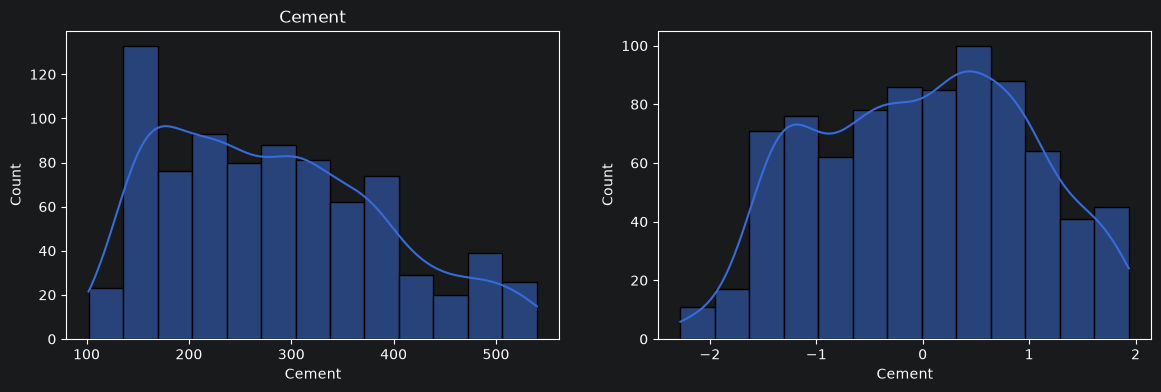

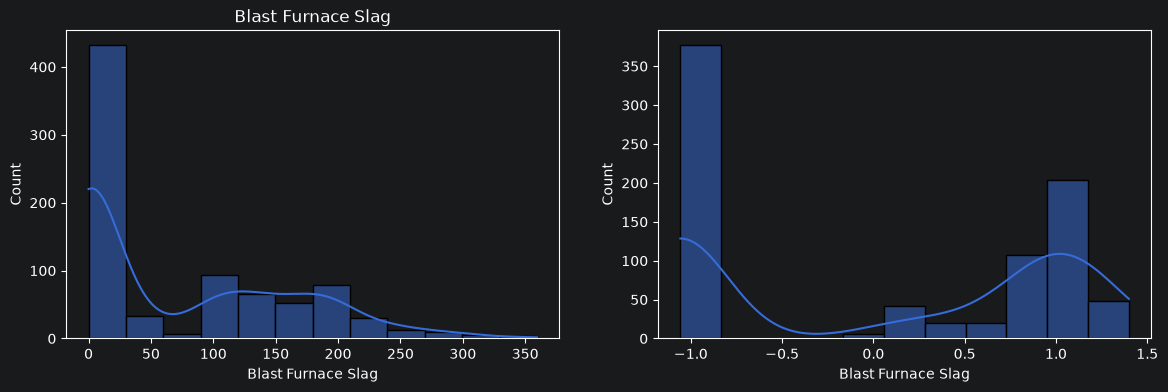

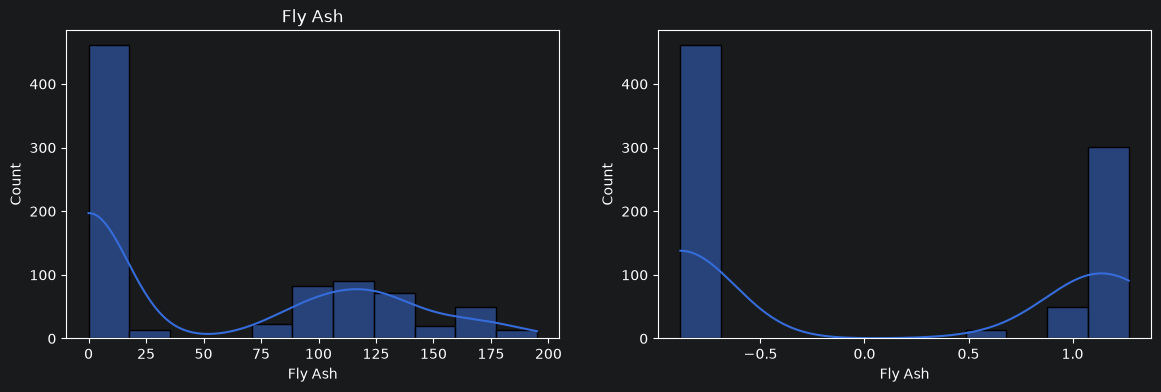

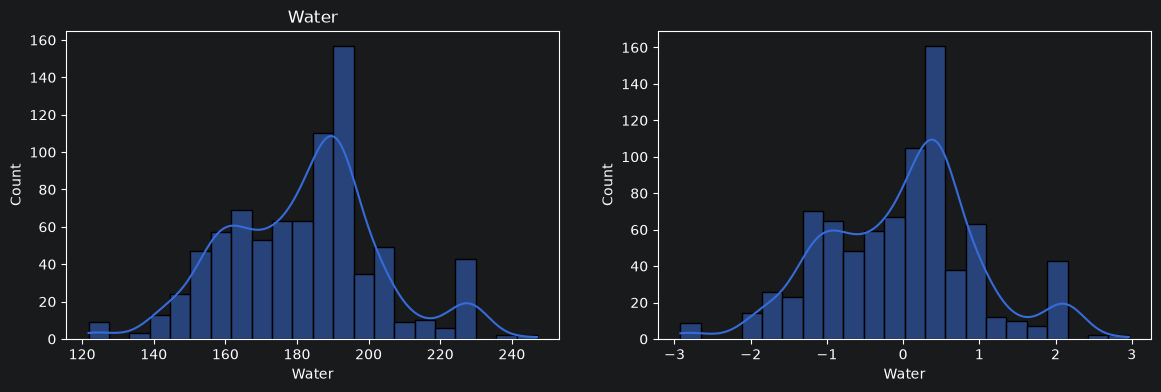

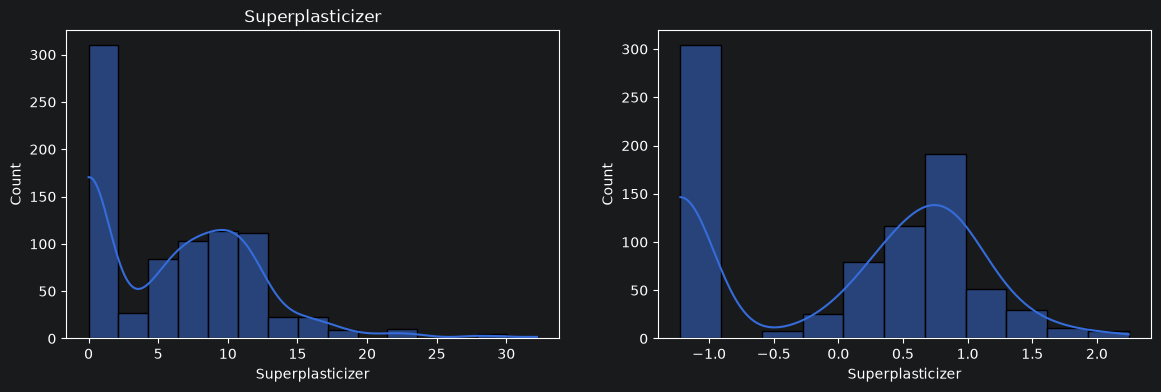

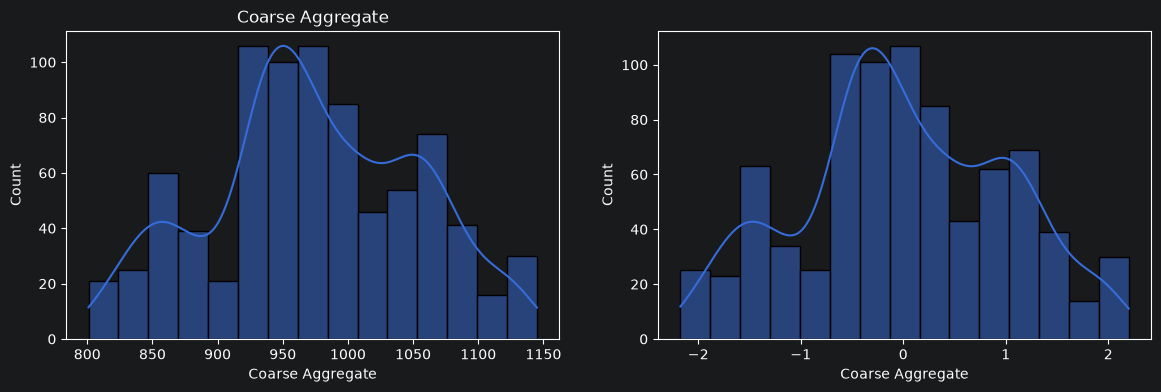

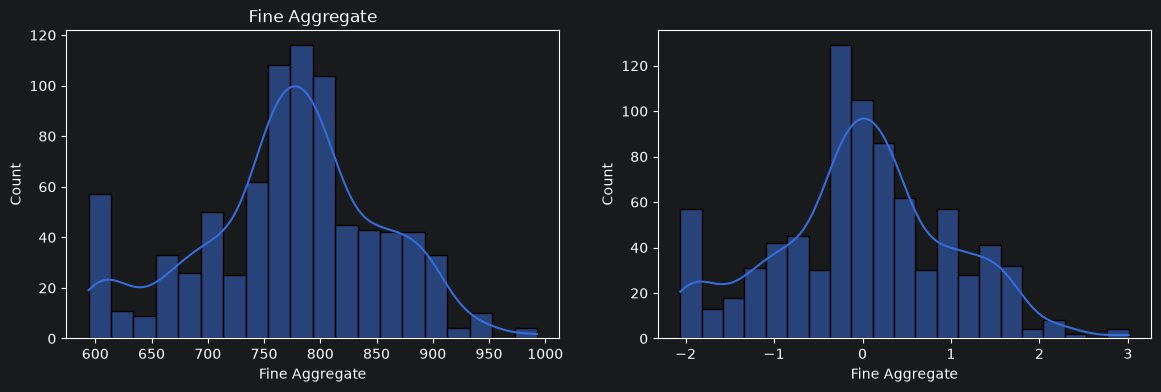

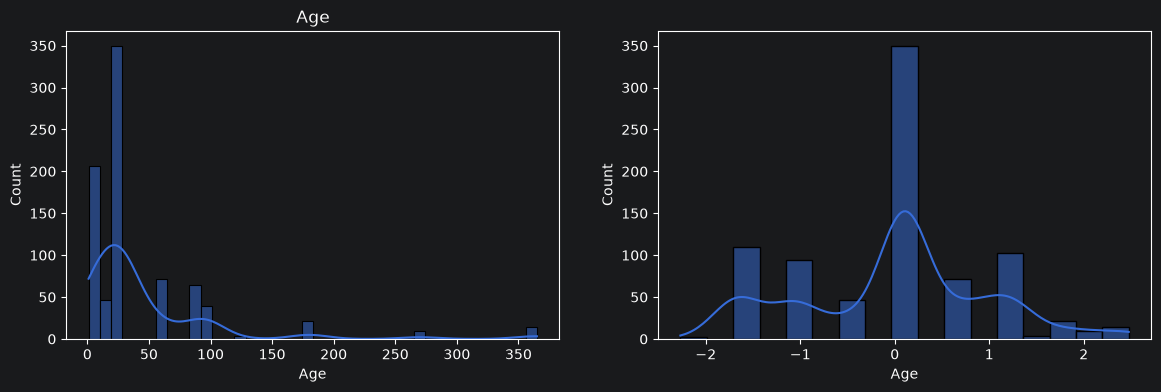

In [180]:
for col in x_train_transformed2:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(x_train[col], kde=True)
    plt.title(col)

    plt.subplot(122)
    sns.histplot(x_train_transformed2[col], kde=True)

In [182]:
pd.DataFrame({'cols':x_train.columns, 'box_cox_lambdas':pt.lambdas_, 'Yeo_Johnson' : pt1.lambdas_})

,cols,box_cox_lambdas,Yeo_Johnson
0,Cement,0.169544,0.174348
1,Blast Furnace Slag,0.016633,0.015715
2,Fly Ash,-0.136480,-0.161447
3,Water,0.808438,0.771307
4,Superplasticizer,0.264160,0.253935
5,Coarse Aggregate,1.129395,1.130050
6,Fine Aggregate,1.830764,1.783100
7,Age,0.001771,0.019885
